# La ecuación 11 y el flujo de entropía por el borde

Explica la diferencia entre las corridas **"L1 paper" / "L2 paper"** y **"L1 corrected" / "L2 corrected"**
de `wpinn_best.ipynb`, usando sólo la notación del paper: $H$, $\eta$, $Q[u;c]$, $\Omega$, $\mathcal{L}_0$, $\mathcal{L}_1$.

> **Idea.** El término que agrega la ecuación 11 es la desigualdad de Kruzhkov (ec. 9) probada contra
> $\varphi \equiv 1$. A diferencia de las $\varphi$ de $\mathcal{L}_0$, la función $1$ **no se anula en el borde**, así
> que al integrar sobrevive un término de borde, $\oint_{\partial\Omega} Q[u;c]\,(n_x + n_y)\,ds$. La ecuación 11 lo
> omite, y en el choque móvil esa omisión castiga a la solución correcta.

Al final se verifica numéricamente con la solución exacta, sin entrenar ninguna red.

## 1. Lo que dice el paper

La ley de conservación (ec. 7) es

$$u_t + H(u)_x + H(u)_y = 0 \quad \text{en } \Omega \times [0, T], \qquad H(u) = \frac{u^2}{2}.$$

La entropía de Kruzhkov es $\eta(u) = |u - c|$, con flujo de entropía $Q[u;c] = \mathrm{sign}(u - c)\,\big(H(u) - H(c)\big)$.
La solución de entropía cumple, para toda $c \in \mathbb{R}$ (ec. 9),

$$\partial_t |u - c| + (\partial_x + \partial_y)\, Q[u;c] \;\le\; 0. \tag{9}$$

Las pérdidas que nos importan:

$$\mathcal{L}_0(u, \varphi, c) = -\int_{[0,T]}\!\int_\Omega \Big(|u - c|\,\partial_t\varphi + Q[u;c]\,(\partial_x\varphi + \partial_y\varphi)\Big)\,dx\,dy\,dt, \tag{10}$$

$$\mathcal{L}_1(u, \varphi, c) = \mathcal{L}_0(u, \varphi, c) + \frac{d}{dt}\int_\Omega \eta(u)\,dx\,dy. \tag{11}$$

Ambas piden "$\le 0$" (el ReLU de la ec. 13 sólo castiga la parte positiva).

## 2. De dónde sale el término de la ecuación 11

### 2.1 En $\mathcal{L}_0$ no hay borde porque $\varphi$ se anula ahí

$\mathcal{L}_0$ es la ec. 9 multiplicada por $\varphi \ge 0$ e integrada por partes. En $x$ e $y$:

$$\int_\Omega \varphi\,(\partial_x + \partial_y) Q[u;c]\,dx\,dy = -\int_\Omega Q[u;c]\,(\partial_x\varphi + \partial_y\varphi)\,dx\,dy \;+\; \oint_{\partial\Omega} \varphi\, Q[u;c]\,(n_x + n_y)\,ds,$$

con $(n_x, n_y)$ la normal exterior. El paper pide $\varphi$ con soporte compacto en $\Omega$ (en el código, la ventana
$(1-x^2)(1-y^2)$), así que $\varphi = 0$ en $\partial\Omega$ y **el término de borde desaparece**.

### 2.2 El término de la ecuación 11 es el caso $\varphi \equiv 1$

Si en la ec. 9 se toma $\varphi \equiv 1$, es decir, se integra sobre $\Omega$ sin peso:

$$\underbrace{\int_\Omega \partial_t |u - c|\,dx\,dy}_{=\;\frac{d}{dt}\int_\Omega \eta(u)\,dx\,dy} \;+\; \int_\Omega (\partial_x + \partial_y)\, Q[u;c]\,dx\,dy \;\le\; 0.$$

El primer término es justo el de la ec. 11. El segundo **no desaparece**: la función $1$ no se anula en el borde. Por
el teorema de la divergencia aplicado al campo $(Q[u;c],\, Q[u;c])$,

$$\int_\Omega (\partial_x + \partial_y)\, Q[u;c]\,dx\,dy = \oint_{\partial\Omega} Q[u;c]\,(n_x + n_y)\,ds.$$

Resultado, la ec. 9 integrada sobre $\Omega$:

$$\boxed{\;\frac{d}{dt}\int_\Omega \eta(u)\,dx\,dy \;+\; \oint_{\partial\Omega} Q[u;c]\,(n_x + n_y)\,ds \;\le\; 0\;}$$

Se lee como un balance: la entropía dentro de $\Omega$ **más la que sale por $\partial\Omega$** no puede aumentar. Si
entra entropía por el borde (integral de borde negativa), la de adentro **sí puede** aumentar.

### 2.3 Lo que impone la ecuación 11

| | Condición que se impone |
|---|---|
| ec. 11 tal como está escrita ("paper") | $\dfrac{d}{dt}\displaystyle\int_\Omega \eta(u) \le 0$ |
| ec. 9 integrada sobre $\Omega$ ("corrected") | $\dfrac{d}{dt}\displaystyle\int_\Omega \eta(u) + \oint_{\partial\Omega} Q[u;c]\,(n_x + n_y)\,ds \le 0$ |

Las dos coinciden **sólo si la integral de borde es cero**: dominio periódico en todas las direcciones, o una solución
que no hace pasar entropía por $\partial\Omega$. En el choque móvil no pasa: por la cara $x = -1$ entra todo el tiempo $u = 1$.

## 3. Cuentas exactas para el choque móvil

La solución exacta es $u = 1$ si $x < x_s(t)$ y $u = 0$ si $x > x_s(t)$, con $x_s(t) = t/2$. No depende de $y$, y
$\Omega = [-1, 1]^2$ tiene alto 2.

### 3.1 El término de la ecuación 11

A la izquierda del choque hay un rectángulo de ancho $x_s + 1$ donde $\eta(u) = |1 - c|$, y a la derecha uno de ancho
$1 - x_s$ donde $\eta(u) = |c|$:

$$\int_\Omega \eta(u)\,dx\,dy = 2\Big[(x_s + 1)\,|1 - c| + (1 - x_s)\,|c|\Big]
\quad\Longrightarrow\quad \frac{d}{dt}\int_\Omega \eta(u)\,dx\,dy = 2\, x_s'\,\big(|1 - c| - |c|\big) = |1 - c| - |c|.$$

Al avanzar, el choque cambia una franja de $u = 0$ por $u = 1$. Si $c < 1/2$, $u = 1$ está más lejos de $c$ que $u = 0$:
**$\int_\Omega \eta(u)$ aumenta y la ec. 11 lo castiga.**

### 3.2 El término de borde

| cara | $(n_x, n_y)$ | $n_x + n_y$ | valor de $u$ |
|---|---|---|---|
| $x = 1$ | $(1, 0)$ | $+1$ | $0$ |
| $x = -1$ | $(-1, 0)$ | $-1$ | $1$ |
| $y = 1$ | $(0, 1)$ | $+1$ | igual que en $y = -1$ |
| $y = -1$ | $(0, -1)$ | $-1$ | igual que en $y = 1$ |

Las caras $y = \pm 1$ se cancelan (mismo $u$, signo opuesto; en el código, condición periódica). Quedan $x = \pm 1$,
cada una de largo 2:

$$\oint_{\partial\Omega} Q[u;c]\,(n_x + n_y)\,ds = 2\,\big(Q[0;c] - Q[1;c]\big),$$

$$Q[1;c] = \mathrm{sign}(1 - c)\Big(\tfrac12 - \tfrac{c^2}{2}\Big), \qquad Q[0;c] = \mathrm{sign}(-c)\Big(0 - \tfrac{c^2}{2}\Big) = \mathrm{sign}(c)\,\tfrac{c^2}{2}.$$

### 3.3 Juntando todo

| rango de $c$ | $\dfrac{d}{dt}\displaystyle\int_\Omega \eta(u)$ (ec. 11) | $\displaystyle\oint_{\partial\Omega} Q[u;c]\,(n_x + n_y)$ | suma (corregida) |
|---|---|---|---|
| $c < 0$ | $1$ | $-1$ | $0$ |
| $0 < c < 1$ | $1 - 2c$ | $2c^2 - 1$ | $-2c(1 - c)$ |
| $c > 1$ | $-1$ | $1$ | $0$ |

- **La corregida** da $\le 0$ para todo $c$: la solución exacta la cumple. El $0$ fuera de $[0, 1]$ es la conservación
  de masa (con $c$ fuera del rango de $u$, $\eta$ y $Q$ son $\pm u$ y $\pm H(u)$ más constantes, y la ec. 9 se vuelve la
  ec. 7). El $-2c(1 - c) < 0$ es la entropía que **destruye el choque**: lo que lo hace admisible.
- **La ec. 11** da $1 - 2c > 0$ para $c < 1/2$: **la solución exacta la viola**, y una pérdida construida con ella
  castiga justo a la respuesta correcta.

## 4. Por qué la red prefería un choque quieto

Tómese la "solución" falsa en que el choque **no se mueve** ($u = u_0$ para todo $t$):

- $\int_\Omega \eta(u)$ es constante, así que su derivada es $0$: **la ec. 11 queda satisfecha para todo $c$.** Para esa
  pérdida, el choque quieto es perfecto.
- El término de borde no cambia (en las caras $x = \pm 1$ el valor de $u$ es el mismo): vale $2c^2 - 1$ en $0 < c < 1$ y $1$
  en $c > 1$. La corregida da entonces $2c^2 - 1 > 0$ para $c > 1/\sqrt{2}$: **la corregida castiga al choque quieto.**
  Para $c > 1$ dice "entra masa por $x = -1$ y $\Omega$ no la acumula": conservación de masa violada.

| | choque correcto ($x_s = t/2$) | choque quieto ($x_s = 0$) |
|---|---|---|
| ec. 11 | **castigado** ($c < 1/2$) | aceptado |
| corregida | aceptado | **castigado** ($c > 1/\sqrt{2}$) |

Por eso "L1 paper" y "L2 paper" tienden a dejar el choque cerca de $x = 0$.

## 5. Verificación numérica

Se calculan los dos términos **sobre una malla** (sin usar las fórmulas de arriba) para el choque correcto y el
quieto, y se comparan con la tabla 3.3. $T = 1$, como en `wpinn_best`; como el choque va a velocidad constante, la
derivada en $t$ no depende de $T$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("notebook.mplstyle")

T = 1.0
shock_speed = 0.5
x_grid = np.linspace(-1.0, 1.0, 20001)   # malla fina en x: la solución no depende de y
face_length = 2.0                        # largo de cada cara de Omega = [-1, 1]^2 (y alto en y)
c_values = np.linspace(-0.25, 1.25, 301)


def flux(u):
    # H(u) = u^2 / 2
    return 0.5 * u**2


def entropy_flux(u, c):
    # Q[u; c] = sign(u - c) (H(u) - H(c))
    return np.sign(u - c) * (flux(u) - flux(c))


def shock_profile(time, speed):
    # u = 1 a la izquierda del choque y 0 a la derecha; speed = 0.5 es el correcto, 0 el quieto.
    return np.where(x_grid <= speed * time, 1.0, 0.0)


def entropy_balance(speed):
    # Para cada c devuelve los dos términos del balance, calculados sobre la malla:
    #   entropy_rate          = d/dt int_Omega eta(u)              (el término de la ec. 11)
    #   boundary_entropy_flux = oint_dOmega Q[u; c] (n_x + n_y) ds  (el que la ec. 11 omite)
    entropy_rate = []
    boundary_entropy_flux = []
    for c in c_values:
        # int_Omega |u - c|: integral en x (regla del trapecio) por el alto en y.
        total_entropy_start = face_length * np.trapezoid(np.abs(shock_profile(0.0, speed) - c), x_grid)
        total_entropy_end = face_length * np.trapezoid(np.abs(shock_profile(T, speed) - c), x_grid)
        # El choque avanza a velocidad constante, así que la derivada es el cociente de diferencias.
        entropy_rate.append((total_entropy_end - total_entropy_start) / T)
        # Cara x = 1 (n_x + n_y = +1, u = 0) más cara x = -1 (n_x + n_y = -1, u = 1); las caras y = ±1 se cancelan.
        boundary_entropy_flux.append(face_length * (entropy_flux(0.0, c) - entropy_flux(1.0, c)))
    return np.array(entropy_rate), np.array(boundary_entropy_flux)


moving_entropy_rate, moving_boundary_flux = entropy_balance(speed=shock_speed)
still_entropy_rate, still_boundary_flux = entropy_balance(speed=0.0)

# Comparación con las fórmulas de la tabla 3.3 (choque correcto).
formula_entropy_rate = np.abs(1 - c_values) - np.abs(c_values)
formula_boundary_flux_closed_form = np.where(c_values < 0, -1.0, np.where(c_values > 1, 1.0, 2 * c_values**2 - 1))
print("max |grid - formula|, d/dt int eta     :", np.abs(moving_entropy_rate - formula_entropy_rate).max())
print("max |grid - formula|, boundary integral:", np.abs(moving_boundary_flux - formula_boundary_flux_closed_form).max())

max |grid - formula|, d/dt int eta     : 7.771561172376096e-16
max |grid - formula|, boundary integral: 1.1102230246251565e-16


#### Figura 1: qué castiga cada versión

**Figura 1.** Para cada constante $c$, la cantidad que cada versión exige que sea $\le 0$; la zona sombreada ($> 0$) es
lo que la pérdida **castiga**. Izquierda, el choque correcto: la ec. 11 (gris discontinuo) entra en la zona castigada
para $c < 1/2$ y la corregida (continua) nunca. Derecha, el choque quieto: la ec. 11 vale 0 para todo $c$ (aceptado)
y la corregida entra en la zona castigada para $c > 1/\sqrt{2} \approx 0.71$. Las verticales punteadas marcan $c = 0$ y
$c = 1$, el rango de $u$.

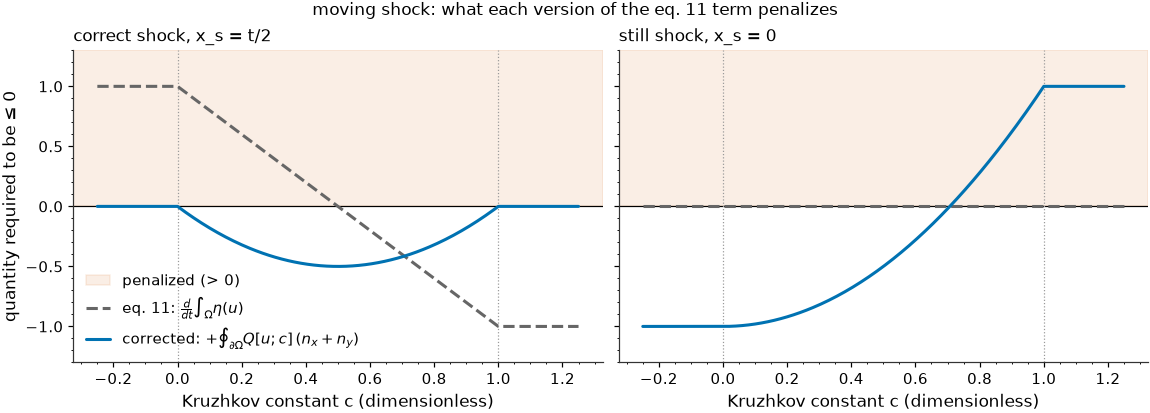

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
cases = [("correct shock, x_s = t/2", moving_entropy_rate, moving_boundary_flux),
         ("still shock, x_s = 0", still_entropy_rate, still_boundary_flux)]
for ax, (title, entropy_rate, boundary_flux) in zip(axes, cases):
    # Sombra: la región que el ReLU castiga.
    ax.axhspan(0.0, 1.3, color="C1", alpha=0.10, label="penalized (> 0)")
    ax.axhline(0.0, color="black", linewidth=0.8)
    for c_limit in (0.0, 1.0):
        ax.axvline(c_limit, color="0.6", linestyle=":", linewidth=0.8)
    ax.plot(c_values, entropy_rate, color="0.4", linestyle="--", linewidth=2.0,
            label=r"eq. 11: $\frac{d}{dt}\int_\Omega \eta(u)$")
    ax.plot(c_values, entropy_rate + boundary_flux, color="C0", linestyle="-", linewidth=2.0,
            label=r"corrected: $+\oint_{\partial\Omega} Q[u;c]\,(n_x+n_y)$")
    ax.set_title(title)
    ax.set_xlabel("Kruzhkov constant c (dimensionless)")
    ax.set_ylim(-1.3, 1.3)
axes[0].set_ylabel("quantity required to be ≤ 0")
axes[0].legend(loc="lower left")
fig.suptitle("moving shock: what each version of the eq. 11 term penalizes")
plt.show()

## 6. Cómo entra en la pérdida

En la wPINN la desigualdad corregida se integra también en $t \in [0, T]$:

$$\underbrace{\int_0^T\!\!\int_\Omega \mathrm{sign}(u - c)\,\partial_t u \;dx\,dy\,dt}_{\int_0^T \frac{d}{dt}\int_\Omega \eta(u)} \;+\; \int_0^T\!\!\oint_{\partial\Omega} Q[u;c]\,(n_x + n_y)\,ds\,dt \;\le\; 0,$$

usando $\partial_t |u - c| = \mathrm{sign}(u - c)\,\partial_t u$. En `wpinn_best.ipynb` (sección 1.6) cada término se estima
por Monte Carlo:

| término | estimación | código |
|---|---|---|
| ec. 11 | $\lvert \Omega \times [0,T] \rvert \cdot \mathrm{media}\big(\mathrm{sign}(u - c)\, u_t\big)$ en los puntos interiores | `integrand + sign * u_t` en `weak_residual` |
| borde | $2T \cdot \big[\mathrm{media}_{x = 1} Q[u;c] - \mathrm{media}_{x = -1} Q[u;c]\big]$ | `boundary_entropy_flux` |

- **"L1 paper" / "L2 paper"** usan sólo el término de la ec. 11: `train_wpinn(level, entropy_boundary_flux=False)`.
- **"L1 corrected" / "L2 corrected"** usan los dos: es el valor por defecto.

En ambos casos se suman a $\mathcal{L}_0$ y pasan por la misma normalización y el mismo ReLU (ec. 13); ésa es la única
diferencia entre las corridas.